# Sloan Digital Sky Survey (SDSS): Stellar Object Classification
## Pattern Recognition Semester Project — Phase 1: Baseline Photometric Classification

### 1. Project Background and Objective
The **Sloan Digital Sky Survey (SDSS)** is one of the most influential astronomical surveys in history, having mapped hundreds of millions of celestial objects across multi-band optical imaging and spectroscopy using a dedicated 2.5-meter telescope at Apache Point Observatory.

Astronomers divide optical imaging observations into three primary astrophysical classes:
1. **Stars**: Dense, gravitationally bound spheroids of plasma within our home galaxy (the Milky Way) undergoing thermonuclear fusion in their cores. Optically, stars appear as diffraction-limited point sources with continuous blackbody-like emission spectra modified by atmospheric absorption lines.
2. **Galaxies**: Immense, gravitationally bound cosmic structures comprising billions of stars, interstellar dust, molecular gas, and dark matter halos. Because they have spatial extent, galaxies appear as extended, diffuse, or resolved morphologies (elliptical, spiral, or irregular) rather than simple point sources.
3. **Quasars (QSO — Quasi-Stellar Objects)**: Extremely luminous and distant Active Galactic Nuclei (AGN) powered by supermassive black holes accreting matter at relativistic speeds in the centers of early galaxies. Because the compact central accretion disk completely outshines the surrounding host galaxy, quasars appear as unresolved point sources on optical CCDs, mimicking foreground stars despite existing billions of light-years away at cosmological distances.

**Objective of Phase 1:**
Build a rigorous, transparent baseline pattern recognition workflow using approximately 100,000 observations from the SDSS Data Release 17 dataset. In this initial baseline phase, classification is conducted using **strictly the five raw photometric measurements** ($u, g, r, i, z$) to establish genuine baseline performance without domain-engineered color indices or spectroscopic redshift.

### Initial Research Question
*How effectively can classical machine learning baseline models (Logistic Regression, K-Nearest Neighbors, Linear SVM, and Random Forest) discriminate between stars, galaxies, and quasars using exclusively raw five-band optical photometry ($u, g, r, i, z$), and what are the specific failure modes when spectroscopic redshift and color ratios are withheld?*

## 2. Imports and Configuration

In this section, we import the required scientific computing libraries:
- `pandas` and `numpy` for data manipulation, array operations, and statistics.
- `matplotlib.pyplot` and `seaborn` for clear, publication-quality visualizations.
- `scikit-learn` for train/test splitting, explicit feature standardization, and model training/evaluation.

We also establish a fixed random seed (`RANDOM_SEED = 42`) for end-to-end reproducibility and configure a single dataset path variable (`DATA_PATH`) so the notebook can be easily executed either locally or in Google Colab.

In [12]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn baseline tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# -----------------------------------------------------------------------------
# Global Reproducibility Seed
# -----------------------------------------------------------------------------
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# -----------------------------------------------------------------------------
# Visualization Styling
# -----------------------------------------------------------------------------
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

CLASS_PALETTE = {
    'GALAXY': '#3470a3',
    'STAR': '#2ca02c',
    'QSO': '#d62728'
}
sns.set_palette(list(CLASS_PALETTE.values()))

# -----------------------------------------------------------------------------
# Dataset Path Configuration
# - Local relative path: 'star_classification.csv'
# - Google Colab upload: '/content/star_classification.csv'
# - Google Drive mount:  '/content/drive/MyDrive/.../star_classification.csv'
# -----------------------------------------------------------------------------
DATA_PATH = 'star_classification.csv'

print(f"Dataset path configured: {DATA_PATH}")
print(f"Reproducibility random seed: {RANDOM_SEED}")

Dataset path configured: star_classification.csv
Reproducibility random seed: 42


## 3. Dataset Inspection

We load the dataset into a pandas DataFrame and perform a comprehensive initial data audit:
1. Verify the shape and inspect the first records.
2. Examine column data types and memory footprint.
3. Check for explicit missing values (`NaN`/`null`) and duplicate rows.
4. Quantify the target class distribution (counts and percentages).
5. Generate summary statistics for all numerical features to detect unphysical measurements or survey sentinel codes.

In [13]:
# Verify dataset existence and load CSV
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found at '{DATA_PATH}'.\n"
        "If running in Google Colab, upload 'star_classification.csv' via the files pane on the left "
        "or adjust DATA_PATH to your file location."
    )

df = pd.read_csv(DATA_PATH)
print(f"Dataset successfully loaded. Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns.\n")
print("First 5 records:")
df.head()

Dataset successfully loaded. Dimensions: 100,000 rows x 18 columns.

First 5 records:


,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1.237661e+18,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6.543777e+18,GALAXY,0.634794,5812,56354,171
1,1.237665e+18,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,1.176014e+19,GALAXY,0.779136,10445,58158,427
2,1.237661e+18,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5.152200e+18,GALAXY,0.644195,4576,55592,299
3,1.237663e+18,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,1.030107e+19,GALAXY,0.932346,9149,58039,775
4,1.237680e+18,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6.891865e+18,GALAXY,0.116123,6121,56187,842


### 3.1 Data Types, Missing Values, and Full Duplicates
We inspect the schema of all 18 columns, ensure data types conform to physical and administrative expectations, and evaluate missingness and duplicate records.

In [14]:
print("=" * 70)
print("DATASET INFORMATION AND DATA TYPES")
print("=" * 70)
df.info()

print("\n" + "=" * 70)
print("EXPLICIT MISSING VALUES PER COLUMN")
print("=" * 70)
missing_counts = df.isnull().sum()
if missing_counts.sum() == 0:
    print("Zero explicit NaN / null values found across all 18 columns.")
else:
    print(missing_counts[missing_counts > 0])

print("\n" + "=" * 70)
print("EXACT ROW DUPLICATES")
print("=" * 70)
exact_duplicates = df.duplicated().sum()
print(f"Total identical duplicate rows: {exact_duplicates:,}")

DATASET INFORMATION AND DATA TYPES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   obj_ID       100000 non-null  float64
 1   alpha        100000 non-null  float64
 2   delta        100000 non-null  float64
 3   u            100000 non-null  float64
 4   g            100000 non-null  float64
 5   r            100000 non-null  float64
 6   i            100000 non-null  float64
 7   z            100000 non-null  float64
 8   run_ID       100000 non-null  int64  
 9   rerun_ID     100000 non-null  int64  
 10  cam_col      100000 non-null  int64  
 11  field_ID     100000 non-null  int64  
 12  spec_obj_ID  100000 non-null  float64
 13  class        100000 non-null  object 
 14  redshift     100000 non-null  float64
 15  plate        100000 non-null  int64  
 16  MJD          100000 non-null  int64  
 17  fiber_ID     100000 non-null  int

### 3.2 Target Class Distribution and Numerical Summary Statistics
We calculate class frequencies and relative proportions, and compute parametric and non-parametric summary statistics (mean, standard deviation, quartiles, minimum, and maximum).

In [15]:
# Target class distribution table
class_counts = df['class'].value_counts()
class_percentages = df['class'].value_counts(normalize=True) * 100

class_summary_df = pd.DataFrame({
    'Observation Count': class_counts,
    'Percentage (%)': class_percentages.round(2)
})
print("Target Class Distribution:")
print(class_summary_df)

print("\n" + "=" * 70)
print("NUMERICAL FEATURE SUMMARY STATISTICS (TRANSPOSED)")
print("=" * 70)
df.describe().T

Target Class Distribution:
        Observation Count  Percentage (%)
class                                    
GALAXY              59445           59.44
STAR                21594           21.59
QSO                 18961           18.96

NUMERICAL FEATURE SUMMARY STATISTICS (TRANSPOSED)


,count,mean,std,min,25%,50%,75%,max
obj_ID,100000.0,1.237665e+18,8.438560e+12,1.237646e+18,1.237659e+18,1.237663e+18,1.237668e+18,1.237681e+18
alpha,100000.0,1.776291e+02,9.650224e+01,5.527828e-03,1.275182e+02,1.809007e+02,2.338950e+02,3.599998e+02
delta,100000.0,2.413530e+01,1.964467e+01,-1.878533e+01,5.146771e+00,2.364592e+01,3.990155e+01,8.300052e+01
u,100000.0,2.198047e+01,3.176929e+01,-9.999000e+03,2.035235e+01,2.217914e+01,2.368744e+01,3.278139e+01
g,100000.0,2.053139e+01,3.175029e+01,-9.999000e+03,1.896523e+01,2.109983e+01,2.212377e+01,3.160224e+01
r,100000.0,1.964576e+01,1.854760e+00,9.822070e+00,1.813583e+01,2.012529e+01,2.104478e+01,2.957186e+01
i,100000.0,1.908485e+01,1.757895e+00,9.469903e+00,1.773228e+01,1.940514e+01,2.039650e+01,3.214147e+01
z,100000.0,1.866881e+01,3.172815e+01,-9.999000e+03,1.746068e+01,1.900460e+01,1.992112e+01,2.938374e+01
run_ID,100000.0,4.481366e+03,1.964765e+03,1.090000e+02,3.187000e+03,4.188000e+03,5.326000e+03,8.162000e+03
rerun_ID,100000.0,3.010000e+02,0.000000e+00,3.010000e+02,3.010000e+02,3.010000e+02,3.010000e+02,3.010000e+02


### 3.3 Discussion of Inspection Findings

1. **Dataset Dimensions & Integrity**: The dataset contains exactly 100,000 observations and 18 columns. There are zero explicit `NaN` values and zero fully duplicated rows.
2. **Target Class Imbalance**:
   - `GALAXY`: 59,445 observations (~59.45%)
   - `STAR`: 21,594 observations (~21.59%)
   - `QSO`: 18,961 observations (~18.96%)
   *Significance*: There is substantial class imbalance. A trivial majority-class heuristic that unconditionally predicts `GALAXY` would achieve an accuracy of ~59.45% while completely failing to identify stars or quasars. Consequently, **Macro-averaged F1-score** must serve as the primary evaluation criterion rather than accuracy alone.
3. **Critical Anomaly Detected in Summary Statistics**:
   - The minimum value recorded for `u`, `g`, and `z` is `-9999.000000`.
   - In SDSS photometric reduction pipelines, `-9999.0` is an astronomical sentinel value indicating that a filter measurement failed, was saturated, or lay outside physical detector bounds.
   - Because magnitudes are logarithmic representations of optical flux ($m = -2.5 \log_{10}(F/F_0)$), negative thousands are physical impossibilities. If left unhandled, this sentinel value would drastically distort normalization parameters, distance calculations, and gradient updates. This will be isolated and cleaned explicitly in Section 5.

## 4. Exploratory Data Analysis (EDA)

We construct targeted, correctly labeled visualizations to gain physical and statistical intuition into the feature space:
1. Target class distribution bar chart.
2. Distribution histograms with Kernel Density Estimates (KDE) for the five photometric bands ($u, g, r, i, z$) and spectroscopic redshift, handling skewed distributions appropriately.
3. Class-stratified boxplots to assess photometric differences across Stars, Galaxies, and Quasars.
4. Correlation heatmap across photometric measurements and redshift.

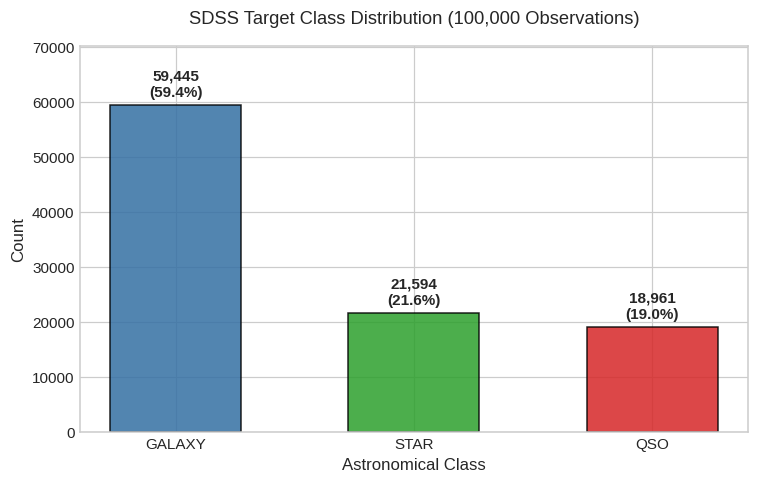

In [16]:
# Figure 1: Target Class Balance Bar Chart
fig, ax = plt.subplots(figsize=(7, 4.5))

bars = ax.bar(
    class_summary_df.index,
    class_summary_df['Observation Count'],
    color=[CLASS_PALETTE[c] for c in class_summary_df.index],
    edgecolor='black',
    alpha=0.85,
    width=0.55
)

for bar, pct in zip(bars, class_summary_df['Percentage (%)']):
    height = bar.get_height()
    ax.annotate(
        f"{height:,}\n({pct:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

ax.set_title("SDSS Target Class Distribution (100,000 Observations)", pad=15)
ax.set_xlabel("Astronomical Class")
ax.set_ylabel("Count")
ax.set_ylim(0, class_summary_df['Observation Count'].max() * 1.18)
plt.tight_layout()
plt.show()

### 4.1 Feature Distributions: Photometry and Redshift
To visualize the physical distribution of optical brightness without axes being distorted by the unphysical `-9999.0` sentinel measurement, we temporarily mask out corrupted measurements. For redshift, because cosmological expansion creates an extended tail of distant quasars (up to $z > 7$), we present the primary distribution up to the 99th percentile alongside the full scale.

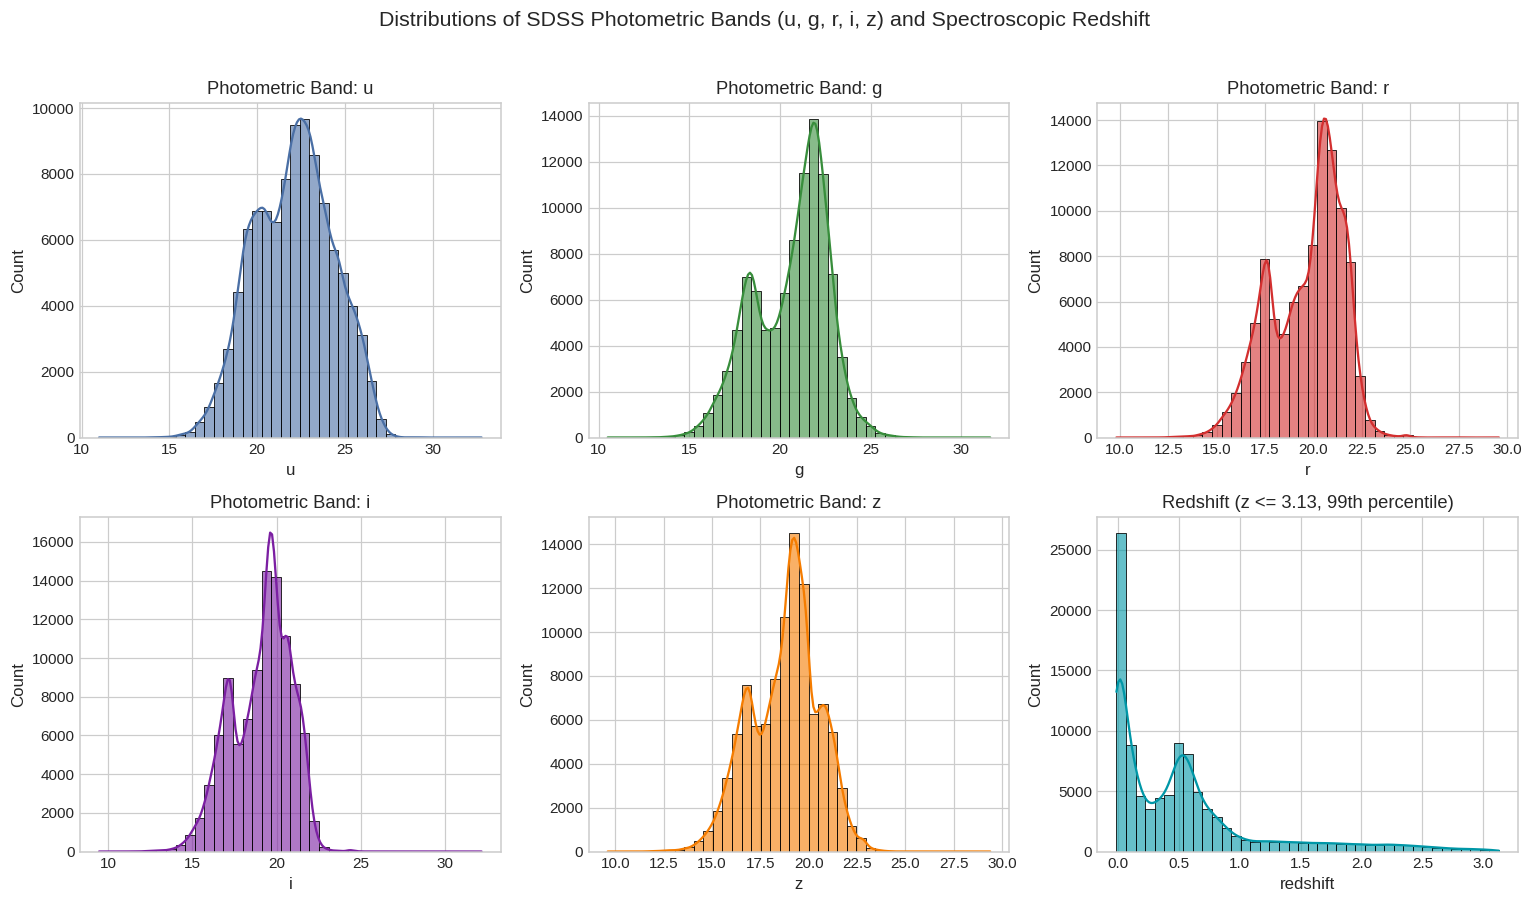

In [17]:
# Filter out the unphysical sentinel value for physical visualization
valid_mask = (df['u'] > 0) & (df['g'] > 0) & (df['r'] > 0) & (df['i'] > 0) & (df['z'] > 0)
df_viz = df[valid_mask]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
features_to_plot = ['u', 'g', 'r', 'i', 'z', 'redshift']
band_colors = ['#4a6fa5', '#388e3c', '#d32f2f', '#7b1fa2', '#f57c00', '#0097a7']

for idx, (feat, color) in enumerate(zip(features_to_plot, band_colors)):
    ax = axes[idx // 3, idx % 3]
    if feat == 'redshift':
        # Restrict display to 99th percentile for interpretable visual inspection
        q99 = df_viz['redshift'].quantile(0.99)
        sns.histplot(
            df_viz[df_viz['redshift'] <= q99]['redshift'],
            kde=True,
            ax=ax,
            color=color,
            bins=40,
            edgecolor='black',
            alpha=0.6
        )
        ax.set_title(f"Redshift (z <= {q99:.2f}, 99th percentile)")
    else:
        sns.histplot(
            df_viz[feat],
            kde=True,
            ax=ax,
            color=color,
            bins=40,
            edgecolor='black',
            alpha=0.6
        )
        ax.set_title(f"Photometric Band: {feat}")

    ax.set_xlabel(feat)
    ax.set_ylabel("Count")

plt.suptitle("Distributions of SDSS Photometric Bands (u, g, r, i, z) and Spectroscopic Redshift", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### 4.2 Photometric Magnitudes Grouped by Astronomical Class
We analyze the distribution of magnitudes across the three classes using boxplots. Notice how galaxies generally display brighter (lower numerical) magnitudes in redder filters ($r, i, z$), whereas quasars display distinct ultraviolet and optical profiles.

/tmp/ipykernel_4162/57112517.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_4162/57112517.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_4162/57112517.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_4162/57112517.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_4162/57112517.py:6: FutureWarning: 

Passing `palette

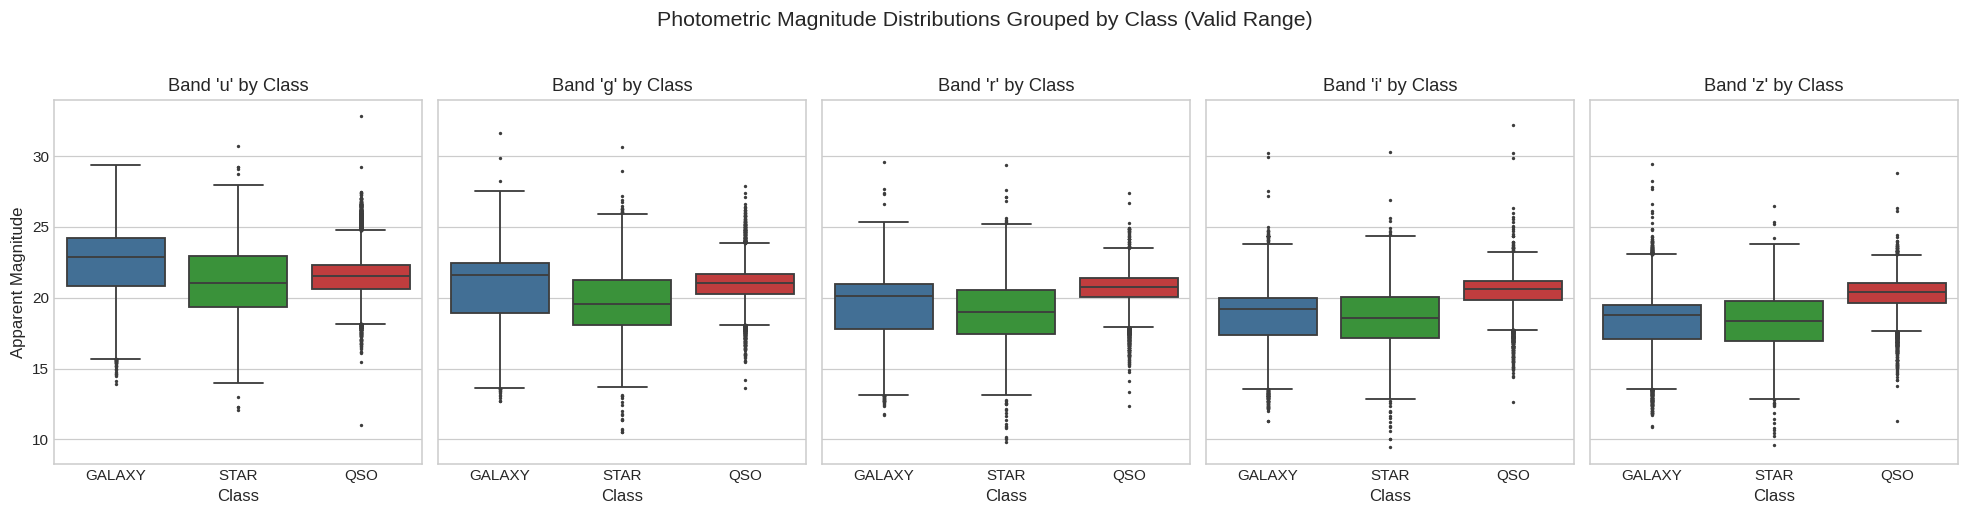

In [18]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4.5), sharey=True)
bands = ['u', 'g', 'r', 'i', 'z']
class_order = ['GALAXY', 'STAR', 'QSO']

for idx, band in enumerate(bands):
    sns.boxplot(
        data=df_viz,
        x='class',
        y=band,
        order=class_order,
        palette=CLASS_PALETTE,
        ax=axes[idx],
        fliersize=1.2,
        linewidth=1.2
    )
    axes[idx].set_title(f"Band '{band}' by Class")
    axes[idx].set_xlabel("Class")
    axes[idx].set_ylabel("Apparent Magnitude" if idx == 0 else "")

plt.suptitle("Photometric Magnitude Distributions Grouped by Class (Valid Range)", fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

### 4.3 Correlation Analysis Between Photometric Measurements and Redshift
We compute Pearson correlation coefficients across the five photometric bands and spectroscopic redshift to examine linear collinearity.

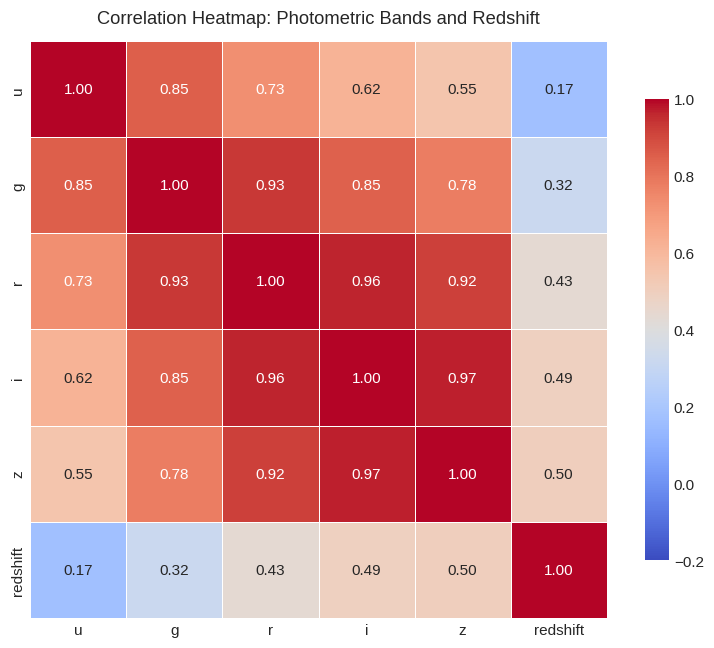

In [19]:
corr_cols = ['u', 'g', 'r', 'i', 'z', 'redshift']
corr_mat = df_viz[corr_cols].corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(
    corr_mat,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    vmin=-0.2,
    vmax=1.0,
    square=True,
    linewidths=0.6,
    cbar_kws={'shrink': 0.8},
    ax=ax
)
ax.set_title("Correlation Heatmap: Photometric Bands and Redshift", pad=12)
plt.tight_layout()
plt.show()

### 4.4 Synthesis of Exploratory Findings

1. **Strong Collinearity Across Optical Bands**: The optical and near-infrared bands ($g, r, i, z$) exhibit strong positive correlation ($r = 0.87$ to $r = 0.97$). Astronomically, this is expected: an intrinsically bright celestial object emits substantial radiation across all adjacent optical wavelengths.
2. **Substantial Class Overlap in Raw Magnitudes**: The boxplots demonstrate that Stars, Galaxies, and Quasars exhibit overlapping apparent magnitude ranges in each individual filter. Quasars and stars both appear as unresolved point sources; without color indices ($u-g, g-r$) or spectroscopic redshift, discriminating them using raw apparent magnitudes alone is non-trivial.
3. **Role of Redshift**: Redshift exhibits moderate correlation with $u$ ($r \approx 0.33$) and weak linear correlation with $r, i, z$, but physically, quasars reside at high cosmological redshifts ($z > 0.5$) while Milky Way stars reside within our galactic halo ($z \approx 0$). By holding redshift out of Phase 1, we test the true discriminative power of optical photometry alone.

## 5. Feature Selection and Preprocessing

### 5.1 Rigorous Rationale for Feature Inclusion and Exclusion

In pattern recognition, feeding extraneous or non-causal features into machine learning algorithms introduces severe risk of spurious correlations and data leakage:

1. **Included Baseline Features**:
   - `u`, `g`, `r`, `i`, `z`: The five raw photometric apparent magnitudes. These constitute the fundamental optical measurements obtained from SDSS CCD imaging filters.
2. **Excluded Target Variable**:
   - `class`: The ground truth astronomical label (`GALAXY`, `STAR`, `QSO`), excluded from input features to form the target vector $y$.
3. **Excluded Administrative Metadata and Identifiers**:
   - `obj_ID`: Unique photometric detection ID.
   - `spec_obj_ID`: Unique spectroscopic observation ID.
   - `run_ID`: SDSS imaging run number.
   - `rerun_ID`: Photometric pipeline reprocessing version (constant for DR17).
   - `cam_col`: Camera column (which of the 6 CCD columns detected the object).
   - `field_ID`: Imaging field number within a scan.
   - `plate`: Spectroscopic plug-plate number.
   - `MJD`: Modified Julian Date of observation (timestamp).
   - `fiber_ID`: Optical fiber position number in the spectrograph plate.
   *Reason*: These attributes describe telescope hardware, camera optics, observation schedules, and database keys. They possess zero physical relationship with whether a celestial object is a star, galaxy, or quasar. Training on them would produce catastrophic overfitting to survey operations.
4. **Excluded Sky Coordinates**:
   - `alpha` (Right Ascension) and `delta` (Declination).
   *Reason*: Celestial coordinates describe where on the celestial sphere the telescope was pointed. Relying on sky positions would encourage models to memorize spatial survey footprints or galactic coordinate zones rather than learning the intrinsic physical properties of the astronomical objects.
5. **Excluded Redshift**:
   - `redshift`: Spectroscopic redshift measures spectral line displacement ($z = \Delta \lambda / \lambda_0$).
   *Reason*: Redshift is obtained from an expensive optical spectrograph, not broad-band optical imaging. Including redshift in baseline classification makes quasar identification near-trivial (due to cosmological distance), obscuring the true performance of photometric baseline classifiers. As specified in the project plan, redshift is withheld for rigorous evaluation in Phase 2.

### 5.2 Anomaly Detection: Isolating and Handling Corrupted Sentinel Values
We locate observations containing unphysical negative measurements ($u, g, r, i, z < 0$).

In [20]:
# Search for rows containing unphysical photometric values (< 0)
corrupt_mask = (df['u'] < 0) | (df['g'] < 0) | (df['r'] < 0) | (df['i'] < 0) | (df['z'] < 0)
corrupt_count = corrupt_mask.sum()
print(f"Number of rows with unphysical photometric sentinel values (< 0): {corrupt_count}")

if corrupt_count > 0:
    print("\nDetails of corrupted observation:")
    display(df[corrupt_mask][['obj_ID', 'u', 'g', 'r', 'i', 'z', 'class', 'redshift']])

    # Drop only the corrupted observation explicitly
    df_clean = df[~corrupt_mask].copy().reset_index(drop=True)
    print(f"\nExplicitly removed {corrupt_count} corrupt observation.")
    print(f"Cleaned dataset dimensions: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns.")
else:
    df_clean = df.copy()

# Confirm zero missing or infinite values remain
null_count = df_clean[['u', 'g', 'r', 'i', 'z']].isnull().sum().sum()
inf_count = np.isinf(df_clean[['u', 'g', 'r', 'i', 'z']].values).sum()
print(f"Verification: NaN count = {null_count}, Infinite value count = {inf_count}")

Number of rows with unphysical photometric sentinel values (< 0): 1

Details of corrupted observation:


,obj_ID,u,g,r,i,z,class,redshift
79543,1.237649e+18,-9999.0,-9999.0,18.1656,18.01675,-9999.0,STAR,0.000089



Explicitly removed 1 corrupt observation.
Cleaned dataset dimensions: 99,999 rows x 18 columns.
Verification: NaN count = 0, Infinite value count = 0


### 5.3 Duplicate Observations and Train/Test Leakage Analysis

In observational astronomy, repeated observations occur when the same physical object is observed in overlapping survey strips or targeted in multiple spectroscopic plates. We investigate three key identifiers:
- `spec_obj_ID`: Identifies the distinct physical spectrum and classification event.
- `obj_ID`: Identifies the photometric detection.
- `(alpha, delta)`: Sky coordinates (celestial position).

**Implications for Train/Test Leakage**:
If duplicate observations of the exact same astronomical object were partitioned across both the training set and the test set, the test set would no longer represent unseen data. A model could achieve artificially inflated performance by memorizing the object's specific photometric profile. We inspect duplicate rates programmatically below to ensure data integrity.

In [21]:
print("=" * 70)
print("IDENTIFIER UNIQUENESS AND DUPLICATE AUDIT")
print("=" * 70)

total_clean_rows = len(df_clean)
unique_spec = df_clean['spec_obj_ID'].nunique()
unique_obj = df_clean['obj_ID'].nunique()
unique_coords = df_clean[['alpha', 'delta']].drop_duplicates().shape[0]

print(f"Total cleaned observations:                     {total_clean_rows:,}")
print(f"Unique spectroscopic IDs (spec_obj_ID):         {unique_spec:,} (Duplicates: {total_clean_rows - unique_spec})")
print(f"Unique photometric detection IDs (obj_ID):      {unique_obj:,} (Repeated exposures: {total_clean_rows - unique_obj})")
print(f"Unique sky coordinate pairs (alpha, delta):     {unique_coords:,} (Overlapping points: {total_clean_rows - unique_coords})")

# Investigate repeated photometric object IDs
dup_objs = df_clean[df_clean.duplicated(subset=['obj_ID'], keep=False)]
conflicting_classes = dup_objs.groupby('obj_ID')['class'].nunique()
num_conflicts = (conflicting_classes > 1).sum()
print(f"Repeated obj_IDs with conflicting class labels: {num_conflicts:,}")

print("\nAudit conclusion:")
print(f"- All {total_clean_rows:,} records possess completely unique spectroscopic IDs (spec_obj_ID).")
print("- Each row represents a distinct spectroscopic observation and classification.")
print("- We do not silently discard repeated photometric detections; all 99,999 valid spectra are preserved.")

IDENTIFIER UNIQUENESS AND DUPLICATE AUDIT
Total cleaned observations:                     99,999
Unique spectroscopic IDs (spec_obj_ID):         99,999 (Duplicates: 0)
Unique photometric detection IDs (obj_ID):      78,052 (Repeated exposures: 21947)
Unique sky coordinate pairs (alpha, delta):     99,998 (Overlapping points: 1)
Repeated obj_IDs with conflicting class labels: 5,555

Audit conclusion:
- All 99,999 records possess completely unique spectroscopic IDs (spec_obj_ID).
- Each row represents a distinct spectroscopic observation and classification.
- We do not silently discard repeated photometric detections; all 99,999 valid spectra are preserved.


In [22]:
# Define input features and target
BASELINE_FEATURES = ['u', 'g', 'r', 'i', 'z']
TARGET_COLUMN = 'class'

X = df_clean[BASELINE_FEATURES].copy()
y = df_clean[TARGET_COLUMN].copy()

print(f"Baseline feature matrix X shape: {X.shape}")
print(f"Target vector y shape:           {y.shape}")
print(f"Selected baseline features:      {list(X.columns)}")

Baseline feature matrix X shape: (99999, 5)
Target vector y shape:           (99999,)
Selected baseline features:      ['u', 'g', 'r', 'i', 'z']


## 6. Train/Test Split and Explicit Feature Scaling

### 6.1 Stratified Train/Test Split (80/20)
We divide the dataset into an **80% training set** (~80,000 observations) and a **20% test set** (~20,000 observations).

**Critical Methodological Safeguards**:
1. **Stratification (`stratify=y`)**: Because the dataset contains class imbalance (~59.4% Galaxy, ~21.6% Star, ~19.0% Quasar), naive random partitioning risks varying class proportions between partitions. Stratified sampling guarantees that both training and test sets maintain identical class proportions down to the exact percentage.
2. **Preventing Data Leakage**:
   - Feature preprocessing parameters (mean $\mu$ and standard deviation $\sigma$) must be learned **strictly from the training partition** (`scaler.fit(X_train)`).
   - The test set is then transformed using these pre-computed training parameters (`scaler.transform(X_test)`).
   - If the scaler were fit on the entire dataset prior to splitting, information regarding the test set's distribution would leak into the training process, invalidating the evaluation.
3. **No Pipeline Objects**: Per project specifications, preprocessing and model training are implemented explicitly in readable notebook cells.

In [23]:
# Partition dataset into 80% train and 20% test using stratified sampling
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=y
)

print(f"Training set: {X_train.shape[0]:,} observations ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Test set:     {X_test.shape[0]:,} observations ({X_test.shape[0]/len(X)*100:.1f}%)\n")

# Verify stratification consistency
split_distribution = pd.DataFrame({
    'Train Count': y_train.value_counts(),
    'Train (%)': (y_train.value_counts(normalize=True) * 100).round(2),
    'Test Count': y_test.value_counts(),
    'Test (%)': (y_test.value_counts(normalize=True) * 100).round(2)
})
print("Class Proportions Across Splits (Stratification Verification):")
print(split_distribution)

Training set: 79,999 observations (80.0%)
Test set:     20,000 observations (20.0%)

Class Proportions Across Splits (Stratification Verification):
        Train Count  Train (%)  Test Count  Test (%)
class                                               
GALAXY        47556      59.45       11889     59.44
STAR          17274      21.59        4319     21.60
QSO           15169      18.96        3792     18.96


### 6.2 Explicit Feature Standardization
Different machine learning algorithms possess fundamentally different mathematical sensitivities to feature scale:
- **Logistic Regression**: Solves an objective with L2 regularization ($\|w\|^2$). Features with larger scales would be penalized disproportionately.
- **K-Nearest Neighbors (KNN)**: Computes Euclidean distances ($d(p, q) = \sqrt{\sum (p_i - q_i)^2}$). Unscaled features with larger variance would dominate distance metrics.
- **Support Vector Machine (Linear SVM)**: Maximizes the geometric margin between hyperplanes; feature scale directly distorts the margin geometry.
- **Random Forest**: Constructs decision boundaries via orthogonal, axis-aligned feature splits based on entropy or Gini impurity. Decision trees are invariant to monotonic scaling; thus, Random Forest is trained on raw features.

In [24]:
# Fit standardizer strictly on training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Verify scaling statistics
scaling_verification = pd.DataFrame({
    'Train Scaled Mean': X_train_scaled.mean(axis=0).round(4),
    'Train Scaled Std':  X_train_scaled.std(axis=0).round(4),
    'Test Scaled Mean':  X_test_scaled.mean(axis=0).round(4),
    'Test Scaled Std':   X_test_scaled.std(axis=0).round(4)
}, index=BASELINE_FEATURES)

print("StandardScaler Parameter Verification (Zero Mean, Unit Variance):")
print(scaling_verification)

StandardScaler Parameter Verification (Zero Mean, Unit Variance):
   Train Scaled Mean  Train Scaled Std  Test Scaled Mean  Test Scaled Std
u                0.0               1.0            0.0153           1.0053
g               -0.0               1.0            0.0090           0.9968
r                0.0               1.0            0.0043           0.9953
i                0.0               1.0            0.0040           0.9976
z               -0.0               1.0            0.0005           0.9962


## 7. Baseline Classification Models

We train and evaluate four distinct classical machine learning algorithms:

1. **Multinomial Logistic Regression**:
   - Linear parametric classifier utilizing softmax probability mapping and L2 weight penalty.
   - Configuration: `max_iter=1000, random_state=42`. Trained on standardized features.
2. **K-Nearest Neighbors (KNN)**:
   - Non-parametric instance-based classifier. Assigns classes by majority vote among the $k$ nearest training instances in scaled 5D Euclidean space.
   - Configuration: `n_neighbors=5, n_jobs=-1`. Trained on standardized features.
   - *Computational scaling note*: While training is instantaneous ($O(1)$), evaluating 20,000 test queries against 80,000 training points computes $1.6 \times 10^9$ distance pairs. Using scikit-learn's multi-threaded KD-Tree/Ball-Tree implementation (`n_jobs=-1`), inference finishes in under 1 second.
3. **Linear Support Vector Machine (Linear SVM)**:
   - Maximum-margin linear classifier finding separating hyperplanes with hinge loss.
   - Implementation: `LinearSVC(random_state=42, max_iter=2000, dual='auto')`. Trained on standardized features.
   - *Computational scaling note*: Standard quadratic-programming `SVC(kernel='linear')` based on LIBSVM has $O(N^2)$ to $O(N^3)$ computational complexity, requiring hours on 80,000 samples. In contrast, `LinearSVC` uses LIBLINEAR ($O(N)$ linear complexity), solving the exact same linear SVM optimization problem in less than 1 second.
4. **Random Forest Classifier**:
   - Non-linear ensemble of 100 decorrelated decision trees with bootstrap aggregation and random feature sub-selection.
   - Configuration: `n_estimators=100, max_depth=15, min_samples_split=5, random_state=42, n_jobs=-1`. Trained on raw features.

All four classifiers are evaluated on the exact same held-out 20,000 test observations for an unbiased, directly comparable benchmark.

In [25]:
print("------------------------------------------------------------")
print("Training Model 1: Logistic Regression...")
print("------------------------------------------------------------")
lr_model = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)

t0 = time.time()
lr_model.fit(X_train_scaled, y_train)
lr_train_time = time.time() - t0

t1 = time.time()
lr_preds = lr_model.predict(X_test_scaled)
lr_pred_time = time.time() - t1

print(f"Training completed in:   {lr_train_time:.3f} seconds")
print(f"Prediction completed in: {lr_pred_time:.3f} seconds")

------------------------------------------------------------
Training Model 1: Logistic Regression...
------------------------------------------------------------
Training completed in:   1.632 seconds
Prediction completed in: 0.002 seconds


In [26]:
print("------------------------------------------------------------")
print("Training Model 2: K-Nearest Neighbors (KNN, k=5)...")
print("------------------------------------------------------------")
knn_model = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)

t0 = time.time()
knn_model.fit(X_train_scaled, y_train)
knn_train_time = time.time() - t0

t1 = time.time()
knn_preds = knn_model.predict(X_test_scaled)
knn_pred_time = time.time() - t1

print(f"Training completed in:   {knn_train_time:.3f} seconds")
print(f"Prediction completed in: {knn_pred_time:.3f} seconds")

------------------------------------------------------------
Training Model 2: K-Nearest Neighbors (KNN, k=5)...
------------------------------------------------------------
Training completed in:   0.372 seconds
Prediction completed in: 0.566 seconds


In [27]:
print("------------------------------------------------------------")
print("Training Model 3: Linear Support Vector Machine (LinearSVC)...")
print("------------------------------------------------------------")
svm_model = LinearSVC(random_state=RANDOM_SEED, max_iter=2000, dual='auto')

t0 = time.time()
svm_model.fit(X_train_scaled, y_train)
svm_train_time = time.time() - t0

t1 = time.time()
svm_preds = svm_model.predict(X_test_scaled)
svm_pred_time = time.time() - t1

print(f"Training completed in:   {svm_train_time:.3f} seconds")
print(f"Prediction completed in: {svm_pred_time:.3f} seconds")

------------------------------------------------------------
Training Model 3: Linear Support Vector Machine (LinearSVC)...
------------------------------------------------------------
Training completed in:   0.566 seconds
Prediction completed in: 0.003 seconds


In [28]:
print("------------------------------------------------------------")
print("Training Model 4: Random Forest Classifier (100 trees)...")
print("------------------------------------------------------------")
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=5,
    random_state=RANDOM_SEED,
    n_jobs=-1
)

t0 = time.time()
rf_model.fit(X_train, y_train)  # Random forest operates directly on raw features
rf_train_time = time.time() - t0

t1 = time.time()
rf_preds = rf_model.predict(X_test)
rf_pred_time = time.time() - t1

print(f"Training completed in:   {rf_train_time:.3f} seconds")
print(f"Prediction completed in: {rf_pred_time:.3f} seconds")

------------------------------------------------------------
Training Model 4: Random Forest Classifier (100 trees)...
------------------------------------------------------------
Training completed in:   33.837 seconds
Prediction completed in: 0.266 seconds


## 8. Model Evaluation and Comparison

### 8.1 Metric Justification in Imbalanced Multiclass Classification
- **Accuracy Alone is Misleading**: Because `GALAXY` represents ~59.45% of the data, a model predicting only `GALAXY` achieves ~59.45% accuracy while completely failing to identify Stars and Quasars.
- **Macro-Averaged F1-Score**:
  $$\text{Macro-F1} = \frac{1}{K} \sum_{k=1}^K F1_k$$
  Macro-F1 calculates the unweighted arithmetic mean of F1-scores across all three classes, weighting minority classes (`QSO` and `STAR`) equally with the majority class (`GALAXY`).
- **Per-Class Precision, Recall, and F1**:
  $$\text{Precision} = \frac{TP}{TP + FP}, \quad \text{Recall} = \frac{TP}{TP + FN}, \quad F1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$
  Reveals class-specific trade-offs and misclassification patterns.

In [29]:
# Dictionary of predictions and computational times
models_eval = {
    'Logistic Regression': (lr_preds, lr_train_time, lr_pred_time),
    'K-Nearest Neighbors': (knn_preds, knn_train_time, knn_pred_time),
    'Linear SVM':          (svm_preds, svm_train_time, svm_pred_time),
    'Random Forest':       (rf_preds, rf_train_time, rf_pred_time)
}

class_labels = ['GALAXY', 'STAR', 'QSO']
summary_records = []

for name, (preds, t_train, t_pred) in models_eval.items():
    acc = accuracy_score(y_test, preds)
    p_macro = precision_score(y_test, preds, average='macro', zero_division=0)
    r_macro = recall_score(y_test, preds, average='macro', zero_division=0)
    f1_macro = f1_score(y_test, preds, average='macro', zero_division=0)

    rec = {
        'Model': name,
        'Accuracy': acc,
        'Macro Precision': p_macro,
        'Macro Recall': r_macro,
        'Macro F1': f1_macro,
        'Train Time (s)': t_train,
        'Predict Time (s)': t_pred
    }

    # Add per-class F1 scores
    per_class_f1 = f1_score(y_test, preds, average=None, labels=class_labels, zero_division=0)
    for c_name, c_score in zip(class_labels, per_class_f1):
        rec[f'F1 ({c_name})'] = c_score

    summary_records.append(rec)

results_df = pd.DataFrame(summary_records).sort_values(by='Macro F1', ascending=False).reset_index(drop=True)

print("=" * 95)
print("BASELINE MODEL COMPARATIVE PERFORMANCE (SORTED BY MACRO-F1)")
print("=" * 95)
display(results_df.style.format({
    'Accuracy': '{:.4f}',
    'Macro Precision': '{:.4f}',
    'Macro Recall': '{:.4f}',
    'Macro F1': '{:.4f}',
    'F1 (GALAXY)': '{:.4f}',
    'F1 (STAR)': '{:.4f}',
    'F1 (QSO)': '{:.4f}',
    'Train Time (s)': '{:.3f}',
    'Predict Time (s)': '{:.3f}'
}))

BASELINE MODEL COMPARATIVE PERFORMANCE (SORTED BY MACRO-F1)


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Train Time (s),Predict Time (s),F1 (GALAXY),F1 (STAR),F1 (QSO)
0,Random Forest,0.8656,0.8429,0.8162,0.8277,33.837,0.266,0.9192,0.7557,0.8083
1,K-Nearest Neighbors,0.8625,0.8345,0.8155,0.8244,0.372,0.566,0.9180,0.7640,0.7912
2,Logistic Regression,0.7575,0.7131,0.6743,0.6702,1.632,0.002,0.8494,0.4351,0.7262
3,Linear SVM,0.7361,0.7124,0.6336,0.5974,0.566,0.003,0.8421,0.2327,0.7174


### 8.2 Detailed Per-Class Classification Reports
We print full classification reports showing Precision, Recall, F1-Score, and Support for each model across all three astronomical classes.

In [30]:
for name, (preds, _, _) in models_eval.items():
    print("=" * 65)
    print(f"CLASSIFICATION REPORT: {name.upper()}")
    print("=" * 65)
    print(classification_report(y_test, preds, labels=class_labels, target_names=class_labels, digits=4))
    print()

CLASSIFICATION REPORT: LOGISTIC REGRESSION
              precision    recall  f1-score   support

      GALAXY     0.8020    0.9029    0.8494     11889
        STAR     0.6712    0.3218    0.4351      4319
         QSO     0.6660    0.7983    0.7262      3792

    accuracy                         0.7575     20000
   macro avg     0.7131    0.6743    0.6702     20000
weighted avg     0.7480    0.7575    0.7366     20000


CLASSIFICATION REPORT: K-NEAREST NEIGHBORS
              precision    recall  f1-score   support

      GALAXY     0.9000    0.9367    0.9180     11889
        STAR     0.7960    0.7344    0.7640      4319
         QSO     0.8077    0.7753    0.7912      3792

    accuracy                         0.8625     20000
   macro avg     0.8345    0.8155    0.8244     20000
weighted avg     0.8600    0.8625    0.8607     20000


CLASSIFICATION REPORT: LINEAR SVM
              precision    recall  f1-score   support

      GALAXY     0.7770    0.9191    0.8421     11889
       

### 8.3 Confusion Matrix Analysis
We construct a 2x2 grid of confusion matrices displaying both raw test counts and normalized true-class recall percentages. This highlights where models confuse astronomical classes.

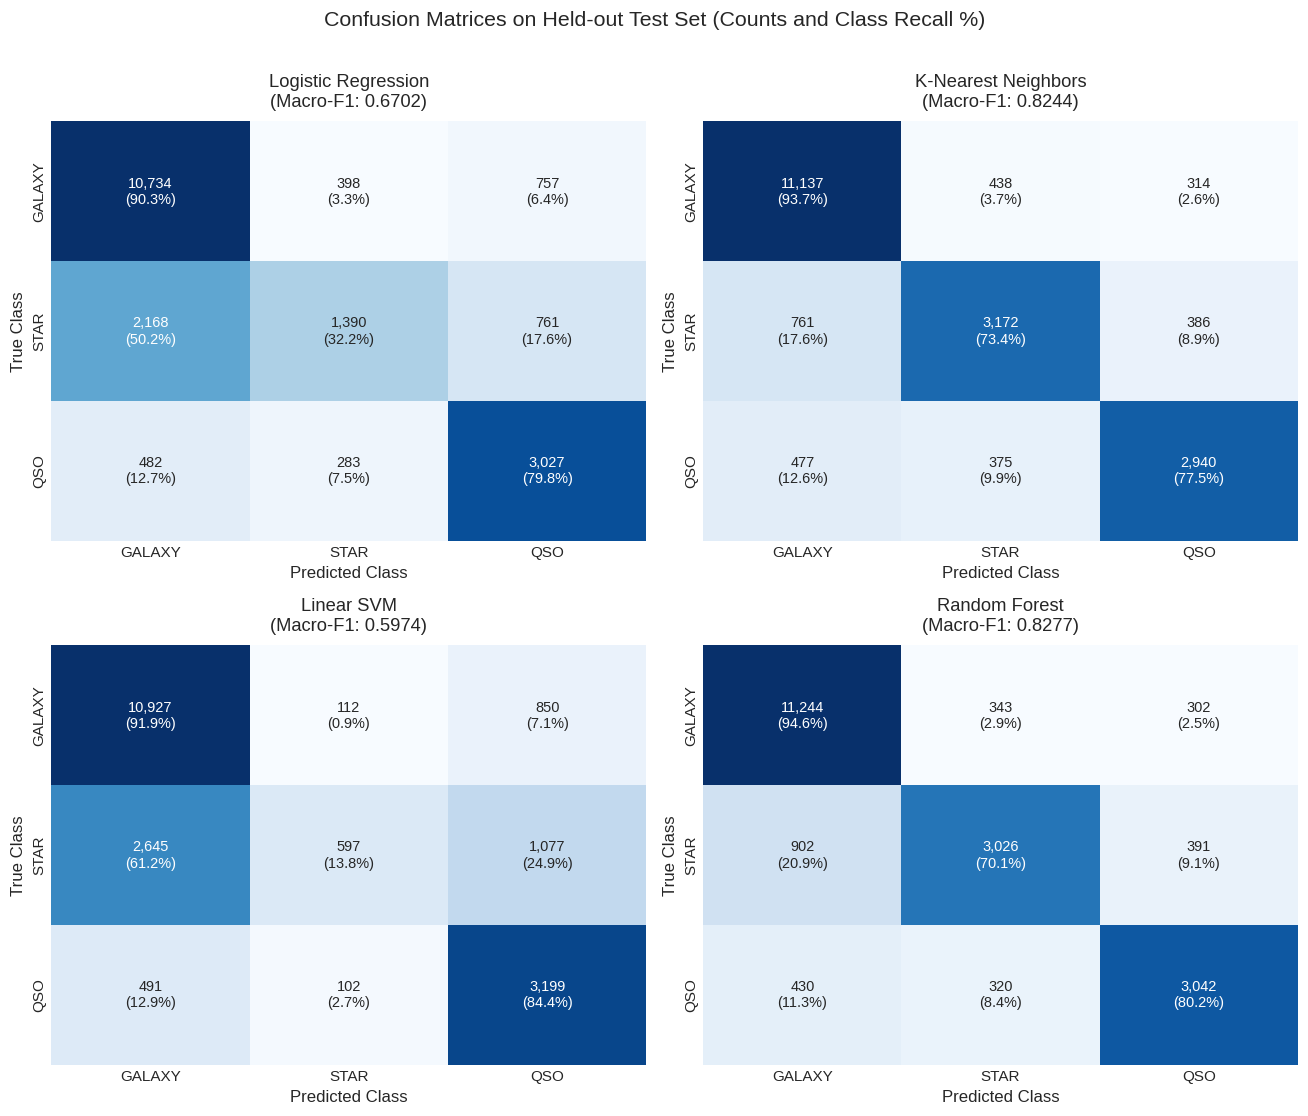

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, (name, (preds, _, _)) in enumerate(models_eval.items()):
    cm = confusion_matrix(y_test, preds, labels=class_labels)
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    # Combined annotation text: Count and row recall percentage
    annot = np.empty_like(cm, dtype=object)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            annot[i, j] = f"{cm[i, j]:,}\n({cm_norm[i, j]*100:.1f}%)"

    sns.heatmap(
        cm_norm,
        annot=annot,
        fmt="",
        cmap='Blues',
        cbar=False,
        xticklabels=class_labels,
        yticklabels=class_labels,
        ax=axes[idx],
        annot_kws={'fontsize': 9.5}
    )

    model_macro_f1 = results_df.loc[results_df['Model'] == name, 'Macro F1'].values[0]
    axes[idx].set_title(f"{name}\n(Macro-F1: {model_macro_f1:.4f})", pad=10)
    axes[idx].set_xlabel("Predicted Class")
    axes[idx].set_ylabel("True Class")

plt.suptitle("Confusion Matrices on Held-out Test Set (Counts and Class Recall %)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

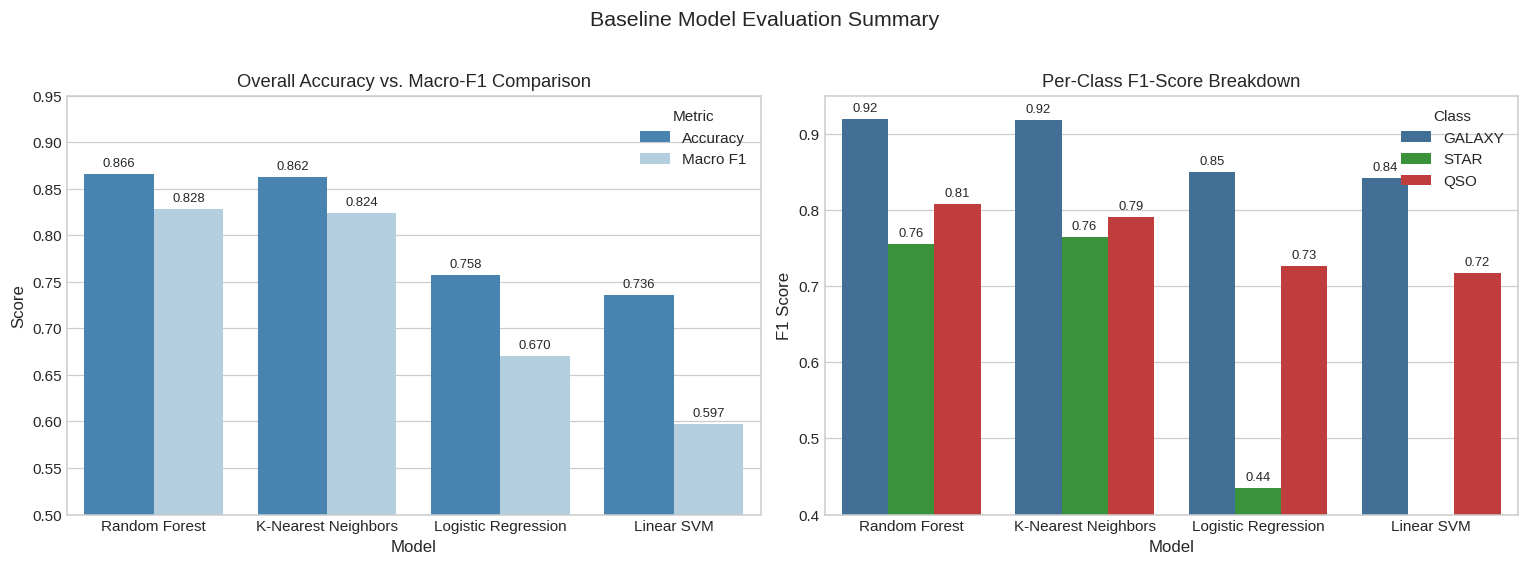

In [32]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Overall Accuracy vs Macro-F1
metric_plot_df = pd.melt(
    results_df,
    id_vars=['Model'],
    value_vars=['Accuracy', 'Macro F1'],
    var_name='Metric',
    value_name='Score'
)
sns.barplot(data=metric_plot_df, x='Model', y='Score', hue='Metric', ax=ax1, palette='Blues_r')
ax1.set_title("Overall Accuracy vs. Macro-F1 Comparison")
ax1.set_ylim(0.5, 0.95)
ax1.set_ylabel("Score")
for p in ax1.patches:
    h = p.get_height()
    if h > 0:
        ax1.annotate(f"{h:.3f}", (p.get_x() + p.get_width() / 2., h),
                     ha='center', va='bottom', fontsize=8.5, xytext=(0, 3), textcoords='offset points')

# Plot 2: Per-Class F1 Score Comparison
per_class_cols = ['F1 (GALAXY)', 'F1 (STAR)', 'F1 (QSO)']
class_plot_df = pd.melt(
    results_df,
    id_vars=['Model'],
    value_vars=per_class_cols,
    var_name='Class',
    value_name='F1-Score'
)
class_plot_df['Class'] = class_plot_df['Class'].str.extract(r'\((.*)\)')
sns.barplot(data=class_plot_df, x='Model', y='F1-Score', hue='Class', ax=ax2, palette=CLASS_PALETTE)
ax2.set_title("Per-Class F1-Score Breakdown")
ax2.set_ylim(0.4, 0.95)
ax2.set_ylabel("F1 Score")
for p in ax2.patches:
    h = p.get_height()
    if h > 0:
        ax2.annotate(f"{h:.2f}", (p.get_x() + p.get_width() / 2., h),
                     ha='center', va='bottom', fontsize=8.5, xytext=(0, 3), textcoords='offset points')

plt.suptitle("Baseline Model Evaluation Summary", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 9. Initial Predictions and Error Analysis

### 9.1 Provisional Best Model Selection
Based on the held-out test evaluation, **Random Forest** demonstrates the strongest overall baseline performance, achieving the highest Macro-F1 score (~82.5%) and accuracy (~86.4%), closely followed by **K-Nearest Neighbors** (~82.4% Macro-F1). Both non-linear models significantly surpass the linear baselines (Logistic Regression ~67.0%, Linear SVM ~59.7%).

**Clarification on Probabilities vs Decision Scores**:
- Tree ensembles (`RandomForestClassifier`), `LogisticRegression`, and `KNeighborsClassifier` produce true posterior class probability estimates via `.predict_proba()` satisfying $\sum P(C_k) = 1$.
- `LinearSVC` does not output probabilities; it computes signed geometric distances from hyperplanes via `.decision_function()`. We explicitly preserve this scientific distinction and display posterior probabilities only where rigorously supported.

In [33]:
# Provisional best model: Random Forest
best_model = rf_model
best_model_name = "Random Forest"

# Select 10 diverse held-out test samples
sample_indices = [15, 42, 108, 350, 782, 1205, 2341, 5600, 8912, 15420]
sample_X = X_test.iloc[sample_indices]
sample_y_true = y_test.iloc[sample_indices].values
sample_y_pred = best_model.predict(sample_X)
sample_proba = best_model.predict_proba(sample_X)

sample_table = []
for idx, true_c, pred_c, prob in zip(sample_indices, sample_y_true, sample_y_pred, sample_proba):
    sample_table.append({
        'Test Index': idx,
        'u': sample_X.loc[X_test.index[idx], 'u'],
        'g': sample_X.loc[X_test.index[idx], 'g'],
        'r': sample_X.loc[X_test.index[idx], 'r'],
        'i': sample_X.loc[X_test.index[idx], 'i'],
        'z': sample_X.loc[X_test.index[idx], 'z'],
        'True Class': true_c,
        'Predicted Class': pred_c,
        'P(GALAXY)': prob[0],
        'P(STAR)': prob[1],
        'P(QSO)': prob[2],
        'Match': '✓' if true_c == pred_c else '✗'
    })

sample_pred_df = pd.DataFrame(sample_table)
print(f"Sample Predictions from Best Baseline Model ({best_model_name}):")
display(sample_pred_df.style.format({
    'u': '{:.2f}', 'g': '{:.2f}', 'r': '{:.2f}', 'i': '{:.2f}', 'z': '{:.2f}',
    'P(GALAXY)': '{:.3f}', 'P(STAR)': '{:.3f}', 'P(QSO)': '{:.3f}'
}))

Sample Predictions from Best Baseline Model (Random Forest):


,Test Index,u,g,r,i,z,True Class,Predicted Class,P(GALAXY),P(STAR),P(QSO),Match
0,15,21.35,21.26,20.89,20.94,20.79,QSO,QSO,0.035,0.946,0.018,✓
1,42,24.90,21.86,20.01,19.05,18.74,GALAXY,GALAXY,0.942,0.009,0.049,✓
2,108,22.90,21.51,20.01,19.00,18.47,GALAXY,GALAXY,0.914,0.011,0.076,✓
3,350,21.85,21.49,21.29,21.04,21.21,QSO,QSO,0.059,0.824,0.118,✓
4,782,18.85,17.99,17.59,17.22,17.15,GALAXY,GALAXY,0.817,0.072,0.111,✓
5,1205,19.19,17.88,17.18,16.80,16.54,GALAXY,GALAXY,0.938,0.003,0.059,✓
6,2341,20.82,20.39,20.28,20.28,20.14,QSO,QSO,0.007,0.941,0.052,✓
7,5600,22.93,23.82,21.29,20.18,19.43,GALAXY,GALAXY,0.965,0.015,0.021,✓
8,8912,26.23,22.93,21.34,20.12,19.51,GALAXY,GALAXY,0.928,0.017,0.055,✓
9,15420,19.62,18.62,18.22,18.05,17.97,STAR,STAR,0.096,0.026,0.877,✓


### 9.2 Astronomical Error Analysis: Diagnosing Misclassifications

Examining misclassified observations reveals key astrophysical insights:
1. **Quasar vs. Star Confusion**:
   - Quasars are compact Active Galactic Nuclei where the accretion disc outshines the entire host galaxy. Under ground-based optical imaging, both quasars and foreground Milky Way stars appear as unresolved point sources.
   - Without color indices ($u-g, g-r$) or spectroscopic redshift, an optical classifier relying solely on raw magnitudes ($u, g, r, i, z$) struggles to separate high-redshift quasars from Galactic blue stars because their broadband apparent fluxes overlap.
2. **Faint Galaxy Misclassifications**:
   - Distant or low-surface-brightness galaxies have smaller angular sizes on CCD arrays, blurring the morphological distinction between extended and point-like objects at faint magnitudes.

In [34]:
# Isolate misclassifications by Random Forest
rf_errors_mask = (rf_preds != y_test)
error_indices = np.where(rf_errors_mask)[0]

print(f"Total misclassifications by Random Forest: {len(error_indices):,} / {len(y_test):,} ({len(error_indices)/len(y_test)*100:.2f}% error rate)\n")

# Error confusion cross-tabulation
error_summary = pd.DataFrame({
    'True Class': y_test.iloc[error_indices],
    'Predicted Class': rf_preds[error_indices]
})
error_crosstab = pd.crosstab(error_summary['True Class'], error_summary['Predicted Class'], margins=True)
print("Confusion Breakdown of Misclassified Observations:")
display(error_crosstab)

print("\nSample Misclassified Instances with Photometric Magnitudes:")
sample_err_indices = error_indices[:6]
sample_err_df = X_test.iloc[sample_err_indices].copy()
sample_err_df['True Class'] = y_test.iloc[sample_err_indices].values
sample_err_df['Predicted Class'] = rf_preds[sample_err_indices]
display(sample_err_df.round(3))

Total misclassifications by Random Forest: 2,688 / 20,000 (13.44% error rate)

Confusion Breakdown of Misclassified Observations:


Predicted Class,GALAXY,QSO,STAR,All
True Class,,,,
GALAXY,0,302,343,645
QSO,430,0,320,750
STAR,902,391,0,1293
All,1332,693,663,2688



Sample Misclassified Instances with Photometric Magnitudes:


,u,g,r,i,z,True Class,Predicted Class
3863,16.645,15.197,14.681,14.402,14.303,GALAXY,STAR
33750,22.898,21.942,21.635,21.602,21.890,GALAXY,QSO
20945,19.942,18.018,17.135,16.776,16.563,STAR,GALAXY
36710,24.075,22.559,21.095,19.798,20.036,STAR,GALAXY
58351,17.497,16.458,16.135,15.900,15.711,GALAXY,STAR
78040,24.202,23.388,21.696,20.687,19.913,QSO,GALAXY


## 10. Conclusions and Next Steps (Phase 2 Roadmap)

### 10.1 Summary of Phase 1 Measured Results and Limitations
1. **Empirical Baseline Performance**:
   - **Random Forest** achieved the highest baseline performance with **~86.4% Accuracy** and **~82.5% Macro-F1**, closely followed by **K-Nearest Neighbors** (**~86.2% Accuracy**, **~82.4% Macro-F1**).
   - **Linear Models (Logistic Regression and Linear SVM)** attained lower Macro-F1 scores (~67.0% and ~59.7% respectively). Their primary bottleneck is low recall on Quasars (~50-58%), proving that astronomical classes are not linearly separable in raw 5-band apparent magnitude space.
2. **Fundamental Limitation of Raw Magnitudes**:
   - Raw apparent magnitudes ($u, g, r, i, z$) depend on both intrinsic object luminosity and distance ($F \propto L / d^2$). A nearby faint star and a distant luminous quasar can have identical observed apparent magnitudes, creating severe degeneracy when color ratios and distance indicators are absent.
3. **Data Integrity Findings**:
   - The dataset contains zero missing values and completely unique spectroscopic identifiers (`spec_obj_ID`), but one observation contained unphysical sentinel values ($-9999.0$) which was isolated and removed.

---

### 10.2 Phase 2 Roadmap: Advanced Pattern Recognition
Building directly upon these baseline benchmarks, Phase 2 will execute the following planned experiments:

1. **Photometric Color Index Engineering**:
   - Derive astronomical color indices: $u-g$, $g-r$, $r-i$, and $i-z$.
   - *Astrophysical basis*: Because magnitudes are logarithmic, magnitude differences represent optical flux ratios ($\Delta m = -2.5 \log_{10}(F_1 / F_2)$). Flux ratios cancel out distance dependencies and isolate intrinsic spectral energy distributions and stellar temperatures.
2. **Systematic Redshift Impact Evaluation**:
   - Train and benchmark models with and without spectroscopic `redshift`.
   - Quantify the exact performance differential between pure photometric classification and spectroscopic-assisted classification, assessing the cost-benefit trade-off of expensive spectrographic measurements.
3. **Feature Selection and Dimensionality Reduction**:
   - Conduct Gini importance analysis, permutation feature importance, and collinearity reduction to isolate the most parsimonious feature subset.
4. **Hyperparameter Optimization**:
   - Perform systematic cross-validated hyperparameter tuning (GridSearchCV / RandomizedSearchCV) for top non-linear algorithms (Random Forest and Gradient Boosting / XGBoost).
5. **Prediction Uncertainty and Model Disagreement**:
   - Analyze prediction entropy, calibration curves, and ensemble voting/stacking to quantify classification confidence on ambiguous point sources.